# scRNA-seq ANALYSIS: QUALITY CONTROL

The pack sctools containing the functions used here can be found in https://github.com/TAndrighetti/SingleCell_Analysis_Tools

**AMBIENTES CONDA:** scRNA_NEW E scRNA_NEW_signaling

In [9]:
# Import sctools functions for data loading and QC analysis
from sctools.io import *
from sctools.qc import *
import scanpy as sc
# Note: sctools package location: https://github.com/TAndrighetti/SingleCell_Analysis_Tools

# **STEP 1:** LOAD RAW DATA

This section loads the raw count matrices from the SevenBridges alignment pipeline output. We load each sample separately to preserve sample metadata and enable per-sample QC analysis.

### What Happens Here

- **Load MTX matrices** (Matrix Market: sparse matrix format for droplet-based protocols like 10x Genomics)
- **Add sample metadata:** K1, K2, W1, W2 to cell observations
- **Infer condition automatically:** "KO" if name starts with K, "WT" otherwise
- **Pre-compute QC metrics:** gene counts, total UMI, mitochondrial percentages, etc.

### Why Separate Loading?

- ✓ Preserves per-sample metadata for later comparisons
- ✓ Enables tracking sample-specific quality variations  
- ✓ Allows per-sample parameter optimization if needed

In [10]:
# Dataset identifier (used for file path construction)
DATASET = "Ffar2"
# Base directory path where all raw data is stored
RAW_BASE = f"/media/tahila/DADOS/HD/2605_scNeu/"

# Sample identifiers: K = KO (knockout), W = WT (wildtype)
# These prefixes are used to automatically assign biological condition
SAMPLES = ['K1', 'K2', 'W1', 'W2']

# Load MTX format matrices (Matrix Market: sparse matrix format commonly used in droplet-based protocols)
# Each sample is loaded with:
#   - Sample name (K1, K2, etc.) added to cell metadata (obs)
#   - Condition automatically inferred: "KO" if name starts with K, "WT" otherwise
#   - format="mtx": specifies input is in MatrixMarket format
#   - include_qc_metrics=True: pre-computes initial QC metrics (gene counts, total counts, etc.)
adatas_dic = {
    "sevenbridges": {name: load_sample(
                                f"{RAW_BASE}/scNeu{DATASET}/01.output_SevenBridges/{DATASET}_{name}",
                                obs_meta={"sample": name, "condition": "KO" if name.startswith("K") else "WT"},
                                format="mtx",
                                include_qc_metrics=True,
                            ) for name in SAMPLES}
}

# Display loaded datasets - check dimensions and metadata
adatas_dic

/home/tahila/miniconda3/envs/scRNA_NEW/lib/python3.10/site-packages/anndata/_core/anndata.py:812: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [106988, 155169, 165809, 199826, 211173]

    Inferred to be: integer

  names = self._prep_dim_index(names, "obs")
INFO:sctools.io:load_sample 'Ffar2_K1': 2597 cells x 23180 genes [mtx].
/home/tahila/miniconda3/envs/scRNA_NEW/lib/python3.10/site-packages/anndata/_core/anndata.py:812: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [12615, 14673, 31467, 42117, 61655]

    Inferred to be: integer

  names = self._prep_dim_index(names, "obs")
INFO:sctools.io:load_sample 'Ffar2_K2': 3925 cells x 25103 genes [mtx].
/home/tahila/miniconda3/envs/scRNA_NEW/lib/python3.10/site-packages/anndata/_core/anndata.py:812: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [24179, 24816, 46709, 80553, 92053]

    Inferred to be: integer

  names = s

{'sevenbridges': {'K1': AnnData object with n_obs × n_vars = 2597 × 23180
      obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
      var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts',
  'K2': AnnData object with n_obs × n_vars = 3925 × 25103
      obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
      var: '

# **STEP 2** - Ambient RNA Correction

### The Problem: Ambient RNA Contamination

In droplet-based protocols (10x Genomics, etc.), not all beads capture single cells. Some capture **ambient RNA** — RNA fragments floating freely in the chamber, derived from lysed cells or cell debris. This creates contamination where your counts include genes from multiple sources.

**Impact on analysis:**
- ❌ Inflates gene counts per cell
- ❌ Introduces spurious genes not expressed by the target cell
- ❌ Particularly problematic for highly expressed genes (housekeeping, hemoglobin, etc.)
- ❌ Interferes with clustering and differential expression

### The Solution: SoupX Algorithm

SoupX estimates and removes ambient RNA contamination:

1. **Identify empty droplets** — Use low-UMI beads as ambient RNA reference
2. **Estimate contamination** — Calculate ρ (rho) = fraction of each cell's UMI from ambient RNA
3. **Adjust counts** — Subtract estimated contamination proportionally from each cell's count matrix

**Literature:** Young et al. (2018) *Genome Biology* — "SoupX is a fast, robust and scalable tool for quality control on raw droplet scRNA-seq counts"

### Implementation

- Load unfiltered bead barcodes (raw matrix with ALL droplets)
- Use as reference for ambient RNA estimation
- Apply SoupX correction to each sample
- Recalculate QC metrics on corrected counts

In [11]:
## Here, you need to load the raw unfiltered count matrix from SevenBridges (or CellRanger), which is used as a reference for ambient RNA estimation in the SoupX correction step. The path to this matrix is constructed based on the RAW_BASE directory and the dataset name.
# Path to raw (pre-filtered) count matrix
raw_unfiltered_matrix_path = f"{RAW_BASE}/01.output_SevenBridges/raw_matrix"
# Load the entire unfiltered dataset (needed as reference for ambient RNA estimation)
raw_unfiltered_adata = load_sample(raw_unfiltered_matrix_path, format="mtx")
# Convert cell barcodes to strings for consistent indexing (avoid type mismatches)
raw_unfiltered_adata.obs_names = raw_unfiltered_adata.obs_names.astype(str)

# Initialize dictionary to store SoupX-corrected objects
adatas_dic["soupx"]={}

# Apply SoupX ambient RNA correction to each sample
for sample, adata in adatas_dic["sevenbridges"].items():
    # AmbientRNA: SoupX contamination correction
    adata_soupx = AmbientRNA(adata, raw_unfiltered_adata)
    # Recalculate QC metrics after correction (counts have changed)
    CalculateQcMetrics(adata_soupx)
    # Store corrected object in dictionary
    adatas_dic["soupx"][sample] = adata_soupx

/home/tahila/miniconda3/envs/scRNA_NEW/lib/python3.10/site-packages/anndata/_core/anndata.py:812: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [68, 84, 672, 991, 1016]

    Inferred to be: integer

  names = self._prep_dim_index(names, "obs")
INFO:sctools.io:load_sample 'raw_matrix': 528975 cells x 30680 genes [mtx].
R[write to console]: 4857 genes passed tf-idf cut-off and 641 soup quantile filter.  Taking the top 100.

R[write to console]: Using 678 independent estimates of rho.

R[write to console]: Estimated global rho of 0.02

R[write to console]: Expanding counts from 13 clusters to 2597 cells.

R[write to console]: 4179 genes passed tf-idf cut-off and 419 soup quantile filter.  Taking the top 100.

R[write to console]: Using 945 independent estimates of rho.

R[write to console]: Estimated global rho of 0.03

R[write to console]: Expanding counts from 17 clusters to 3925 cells.

R[write to console]: 4367 genes passed tf-idf cut-off and 53

In [ ]:
adatas_dic["soupx"]

{'K1': AnnData object with n_obs × n_vars = 2597 × 23180
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
     var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
     uns: 'qc_params'
     layers: 'counts', 'soupX_counts',
 'K2': AnnData object with n_obs × n_vars = 3925 × 25103
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_c

# **STEP 3:** DOUBLET DETECTION & REMOVAL (Scrublet)

### The Problem: Doublets in Droplet Protocols

**Doublets** = 2 or more cells captured in the same droplet

**Why this matters:**
- ❌ ~5–10% expected doublet rate in 10x protocols
- ❌ Merged expression profile appears as artificial hybrid cell type
- ❌ Inflates cell counts and confounds clustering
- ❌ Creates false biological signals
- ❌ Particularly problematic for rare cell type discovery

### The Solution: Scrublet Algorithm

Scrublet identifies doublets through synthetic simulation:

1. **Simulate synthetic doublets** — Randomly merge pairs of real cells
2. **Create mixed training set** — Combine synthetic + real cells
3. **Train classifier** — Machine learning to distinguish real from synthetic
4. **Score each cell** — Assign "doublet probability" score (0–1)
5. **Apply threshold** — Classify high-score cells as doublets

**Why it works:** Real doublets should score similarly to synthetic ones because they have merged gene expression patterns

**Literature:** Wolock et al. (2019) *Cell Systems* — "Scrublet: computational identification of cell doublets in single-cell transcriptomic data"

### Two-Step Process

| Step | Goal | Action |
|------|------|--------|
| **3A** | Verify threshold | Score cells & visualize distribution |
| **3B** | Remove doublets | Filter cells with score > threshold |

**What to look for in 3A:**
- ✓ Clear bimodal distribution (singlets ≠ doublets)
- ❌ Unimodal distribution (threshold ambiguous)
- ❌ Threshold in the middle (poor separation)

----- K1 ------


INFO:sctools.qc:ScoreDoublets: 2597 cells scored [layer=soupX_counts, expected_doublet_rate=0.06].


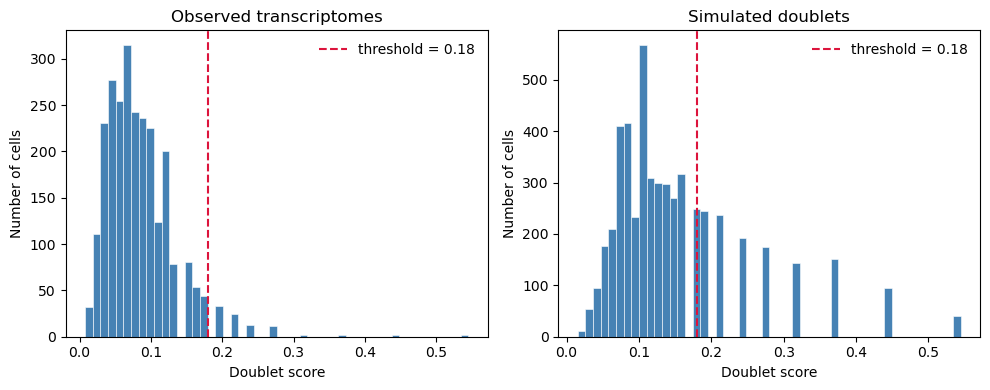

----- K2 ------


INFO:sctools.qc:ScoreDoublets: 3925 cells scored [layer=soupX_counts, expected_doublet_rate=0.06].


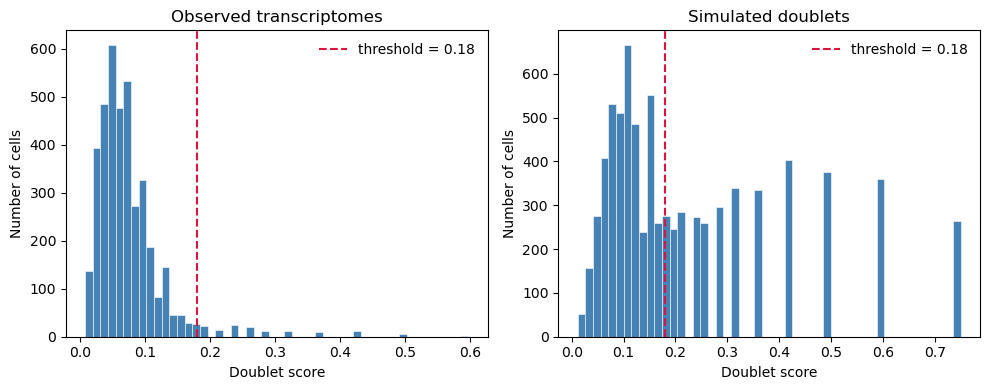

----- W1 ------


INFO:sctools.qc:ScoreDoublets: 3275 cells scored [layer=soupX_counts, expected_doublet_rate=0.06].


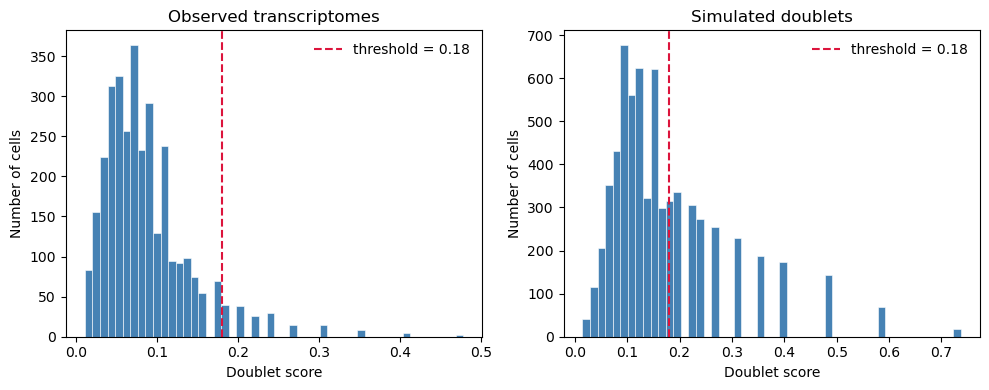

----- W2 ------


INFO:sctools.qc:ScoreDoublets: 3267 cells scored [layer=soupX_counts, expected_doublet_rate=0.06].


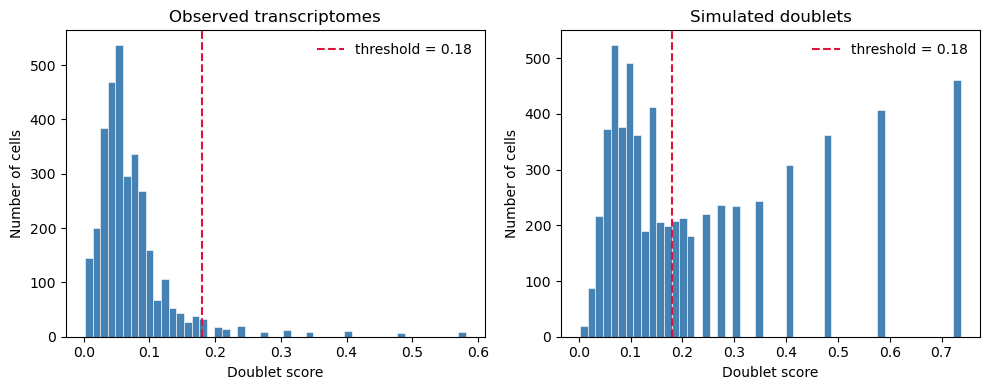

In [12]:
# Doublet detection threshold - probability cutoff for Scrublet
# Cells with scores > threshold are classified as doublets
# We'll verify this threshold visually before applying it
doublet_threshold = 0.18

# Score and visualize doublet predictions for each sample
for sample, adata in adatas_dic["soupx"].items():
    print(f"----- {sample} ------")
    
    # ScoreDoublets: Calculate doublet probability scores for each cell
    # Using SoupX-corrected counts (layer="soupX_counts") for more accurate prediction
    ScoreDoublets(adata, layer="soupX_counts")
    
    # PlotScrubletScores: Visualize the distribution of doublet scores
    # Shows: histogram of scores with threshold line overlaid
    # Look for: clear bimodal distribution (singlets with low score, doublets with high)
    # If distribution is unimodal or threshold falls in the middle, reconsider threshold
    PlotScrubletScores(adata, threshold=doublet_threshold)

## 2. Filter with the chosen threshold

In [13]:
# ==============================================================================
# STEP 3B: FILTER DOUBLETS
# ==============================================================================
# Apply the doublet threshold to remove predicted doublets from all samples.
# After this step, we have "singlet-only" datasets for QC analysis.

# Doublet detection threshold (same as before - verified visually in previous step)
doublet_threshold = 0.18
# Initialize dictionary to store singlet-filtered objects
adatas_dic["scroublet"] = {}

# Filter doublets from each sample using SoupX-corrected data
for sample, adata in adatas_dic["soupx"].items():
    # FilterDoublets: Remove cells with doublet_score > threshold
    # Returns:
    #   - adata_singlets: filtered AnnData with only singlets
    #   - summary: dict with removal stats (n_removed, n_remaining, threshold)
    adata_singlets, summary = FilterDoublets(adata, threshold=doublet_threshold)
    print(f"{sample}: {summary}")
    
    # Recalculate QC metrics on singlet-only data
    # This provides baseline metrics before QC filtering
    CalculateQcMetrics(adata)
    # Store singlet-filtered object in dictionary
    adatas_dic["scroublet"][sample] = adata_singlets

# Display filtered datasets - check cell count reduction after doublet removal
adatas_dic["scroublet"]

INFO:sctools.qc:CallDoublets: threshold=0.180 → 91 doublets (3.5% of 2597 cells).
INFO:sctools.qc:FilterDoublets: removed 91 doublets, 2506 cells remaining.
INFO:sctools.qc:CallDoublets: threshold=0.180 → 159 doublets (4.0% of 3925 cells).
INFO:sctools.qc:FilterDoublets: removed 159 doublets, 3766 cells remaining.


K1: {'n_removed': 91, 'n_remaining': 2506, 'threshold': 0.18}
K2: {'n_removed': 159, 'n_remaining': 3766, 'threshold': 0.18}


INFO:sctools.qc:CallDoublets: threshold=0.180 → 178 doublets (5.4% of 3275 cells).
INFO:sctools.qc:FilterDoublets: removed 178 doublets, 3097 cells remaining.
INFO:sctools.qc:CallDoublets: threshold=0.180 → 137 doublets (4.2% of 3267 cells).
INFO:sctools.qc:FilterDoublets: removed 137 doublets, 3130 cells remaining.


W1: {'n_removed': 178, 'n_remaining': 3097, 'threshold': 0.18}
W2: {'n_removed': 137, 'n_remaining': 3130, 'threshold': 0.18}


{'K1': AnnData object with n_obs × n_vars = 2506 × 23180
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet'
     var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
     uns: 'qc_params', 'scrublet'
     layers: 'counts', 'soupX_counts',
 'K2': AnnData object with n_obs × n_vars = 3766 × 25103
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_co

# **STEP 4:** EXPLORE QC METRICS BEFORE FILTERING

Before filtering, we visualize metric distributions to understand data quality and guide threshold selection.

### Key QC Metrics Explained

| **Metric** | **Normal** | **Low = ?** | **High = ?** |
|:-----------|:-----------|:-----------|:-----------|
| **n_genes_by_counts** | 200–6,000 | Empty droplet, degraded cell | Doublet, large cell |
| **total_counts** | ~1,000–10,000 UMI | Poor recovery, small cell | Large cell, doublet, contamination |
| **pct_counts_mt** | <15% | Healthy tissue | Stressed/dying cell, poor recovery |
| **pct_counts_ribo** | 5–30% | Ribosome loss | Tissue-dependent (normal in some) |
| **pct_counts_hb** | <1% | Most tissues | Blood contamination, RBCs present |

### Healthy Cell Signature

✓ **Positive correlation:** total_counts ↔ n_genes (more UMI = more genes)  
✓ **MT% concentrated low:** <15% for most cells  
✓ **Clear clustering:** Main distribution separates from outliers  

### Quality Issues to Spot

| Issue | Pattern |
|-------|---------|
| **Empty droplets** | Low counts + low genes, clustered at origin |
| **Stressed cells** | High MT% + normal genes = cell damage |
| **Ambient contamination** | High genes relative to counts |
| **Doublets (if unfilt.)** | 2× normal counts and genes |

### Visualizations

1. **Violin plots** — Metric distributions across all cells
2. **Scatter plots** — 2D relationships (counts vs genes, colored by MT%)
3. **Zoomed plots** — Same with y-limits to focus on main distribution

### What to Look For in Visualizations

**Healthy cell signature:**
- Positive correlation: total_counts ↔ n_genes (more UMI = more genes)
- MT% concentrated at lower values (<15%)
- Clear separation of main distribution from outliers

**Quality issues:**
- **Empty droplets:** Clustered at low counts, low genes
- **Stressed cells:** High MT%, normal gene count
- **Ambient contamination:** High genes relative to counts
- **Doublets (if not already filtered):** 2× normal counts and genes

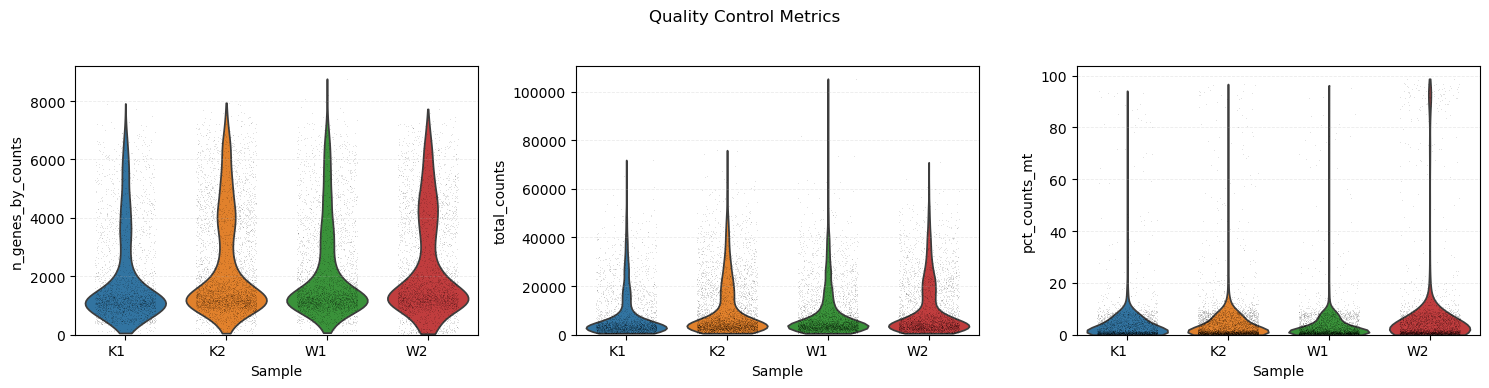

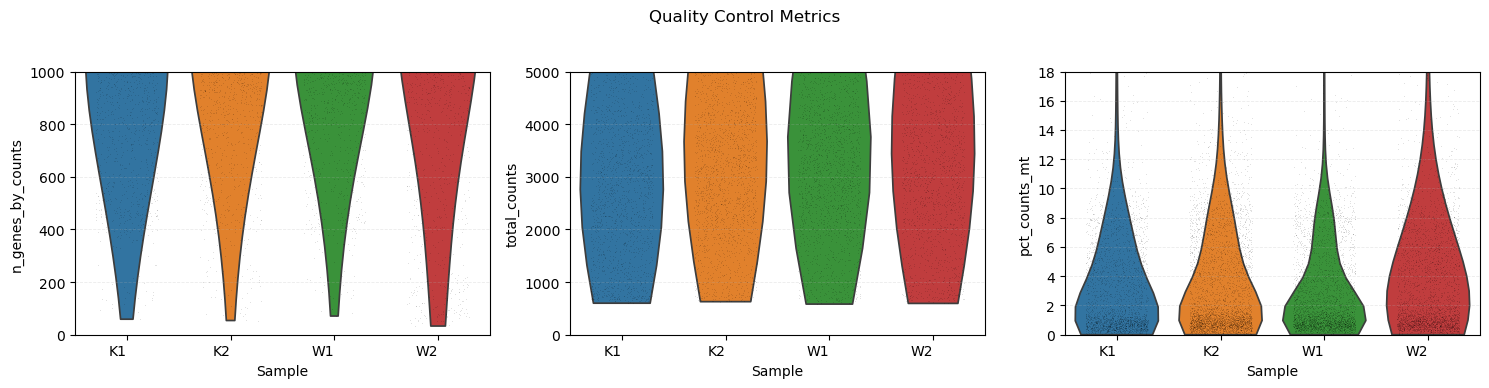

------K1-------


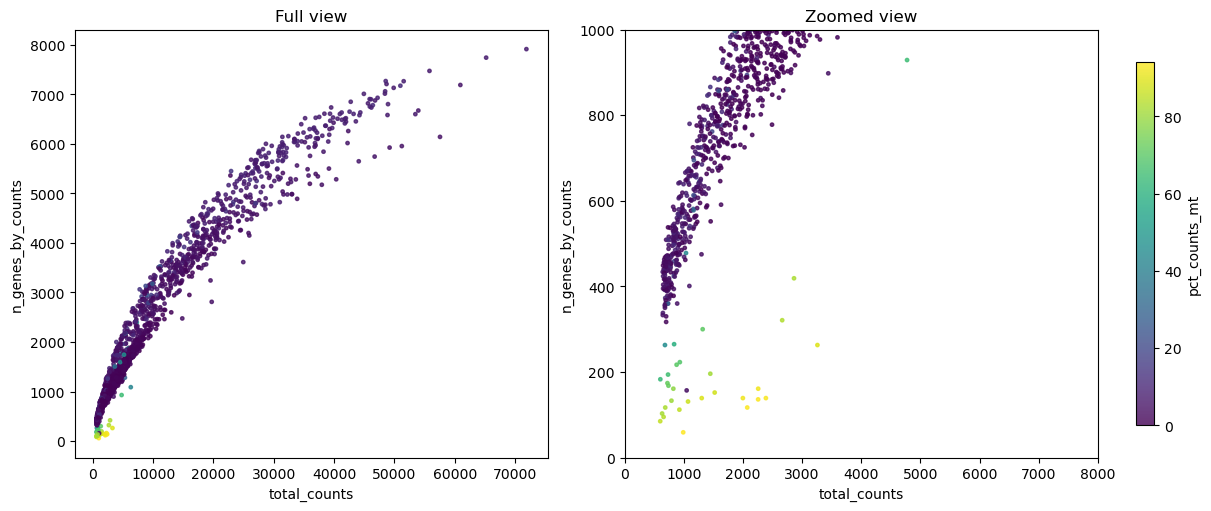

------K2-------


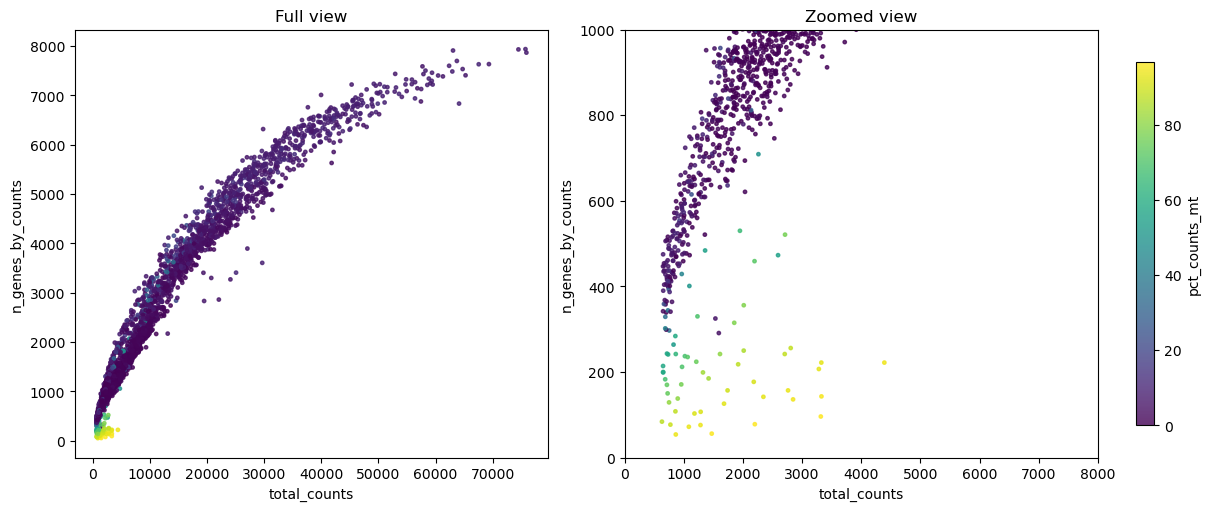

------W1-------


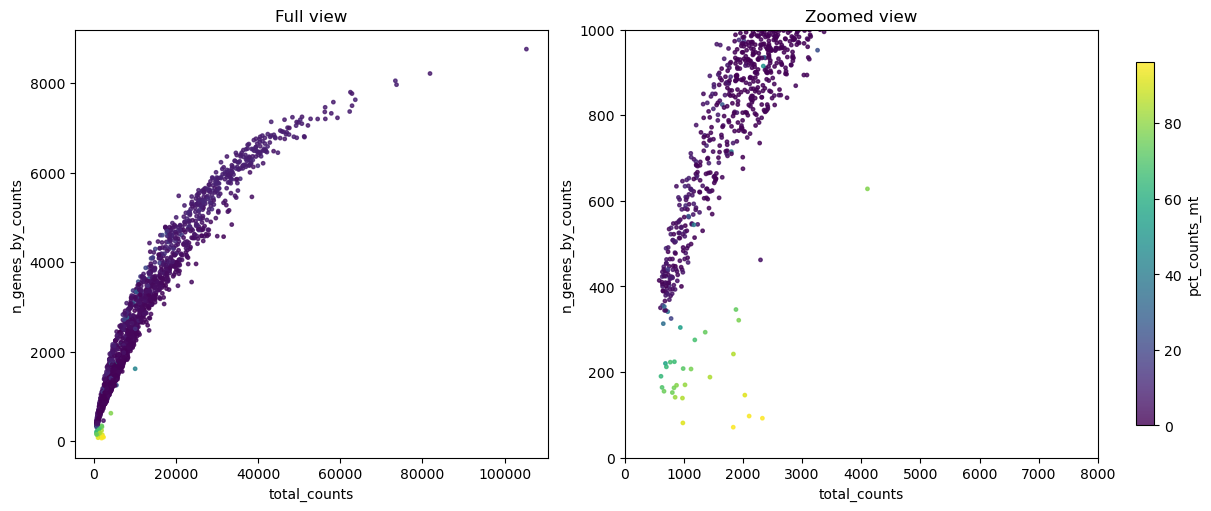

------W2-------


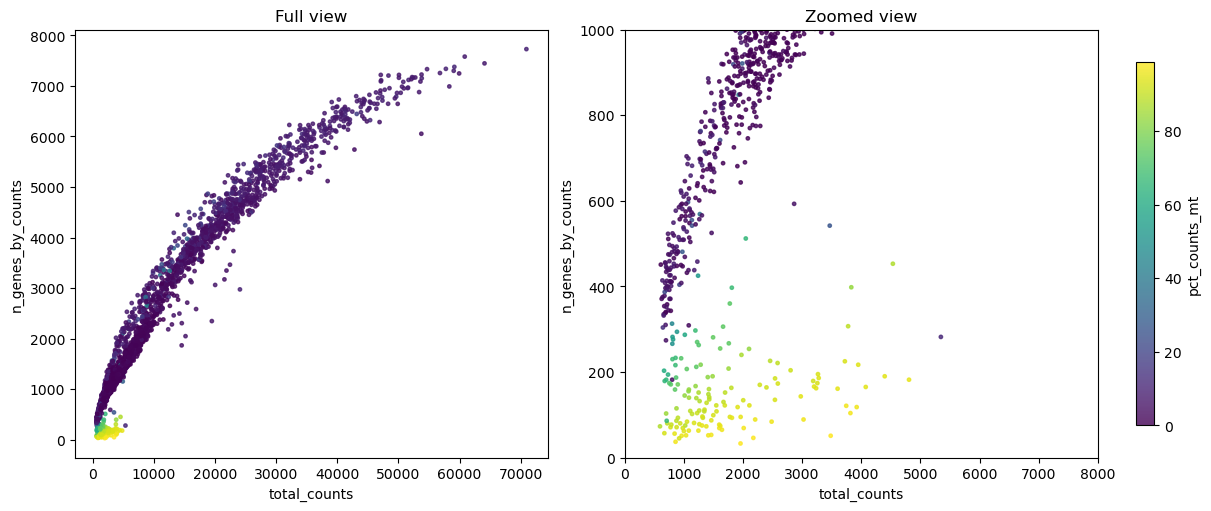

In [14]:
# Visualize QC metrics distribution across all singlet-filtered samples (full range)
PlotQCViolinsGrid(sc.concat(list(adatas_dic["scroublet"].values())))

# Same plot with y-axis limits for better detail visualization
# Helps see the main distribution without extreme outliers compressing the view
PlotQCViolinsGrid(
    sc.concat(list(adatas_dic["scroublet"].values())),
    ymin=0,
    ymax={'n_genes_by_counts':1000, 'total_counts':5000, 'pct_counts_mt':18}
)

# Per-sample scatter plots: detailed 2D relationships
# Relationship between total_counts (x) and n_genes_by_counts (y) reveals:
#   - Normal cells: positive correlation (more counts = more genes)
#   - Empty droplets: low counts, low genes
#   - Doublets: very high counts and genes (2 cells worth)
#   - Stressed cells: high MT% (red color), often lower gene count relative to counts
for sample, adata in adatas_dic["scroublet"].items():
    # Ensure QC metrics are up-to-date for this sample
    CalculateQcMetrics(adata)

    print(f"------{sample}-------")
    # Plot 2D scatter with multiple zoom levels
    # Full zoom: all cells with outliers visible
    # Zoomed views: focus on main distribution to spot quality issues
    _,_ = PlotQCScatterFullZoom(
        adata,
        x="total_counts",
        y="n_genes_by_counts",
        color="pct_counts_mt",  # Color by mitochondrial % to spot stressed cells
    )

This scatter plot reveals a clear separation of low-quality cells: cells with n_genes_by_counts < ~200 exhibit elevated mitochondrial percentages and show a distinct clustering pattern. These characteristics indicate empty droplets or stressed cells. Based on this distribution, we can establish appropriate filtering thresholds.

## EVALUATE THRESHOLD COMBINATIONS

Now we systematically test different filtering thresholds to find the optimal balance between data quality and cell retention.

### The Trade-offs

**Too lenient (low threshold):**
- Keep more cells (higher retention)
- But keep low-quality cells → noise in downstream analysis
- May retain empty droplets, stressed cells, degraded cells

**Too strict (high threshold):**
- Only keep pristine, high-quality cells
- But lose many valid cells, especially rare cell types
- May over-filter and reduce statistical power

### Our Approach: Grid Search

We test **9 combinations**:
- Gene count: 100 | 200 | 500
- MT%: 10 | 15 | 20

**Decision framework:**
- Look for cell retention at ~75–90% (good balance)
- Check that quality metrics improve as expected
- If any sample is drastically different, consider per-sample parameters
- Typical standard for neural tissue: gene_min=200, MT%_max=15

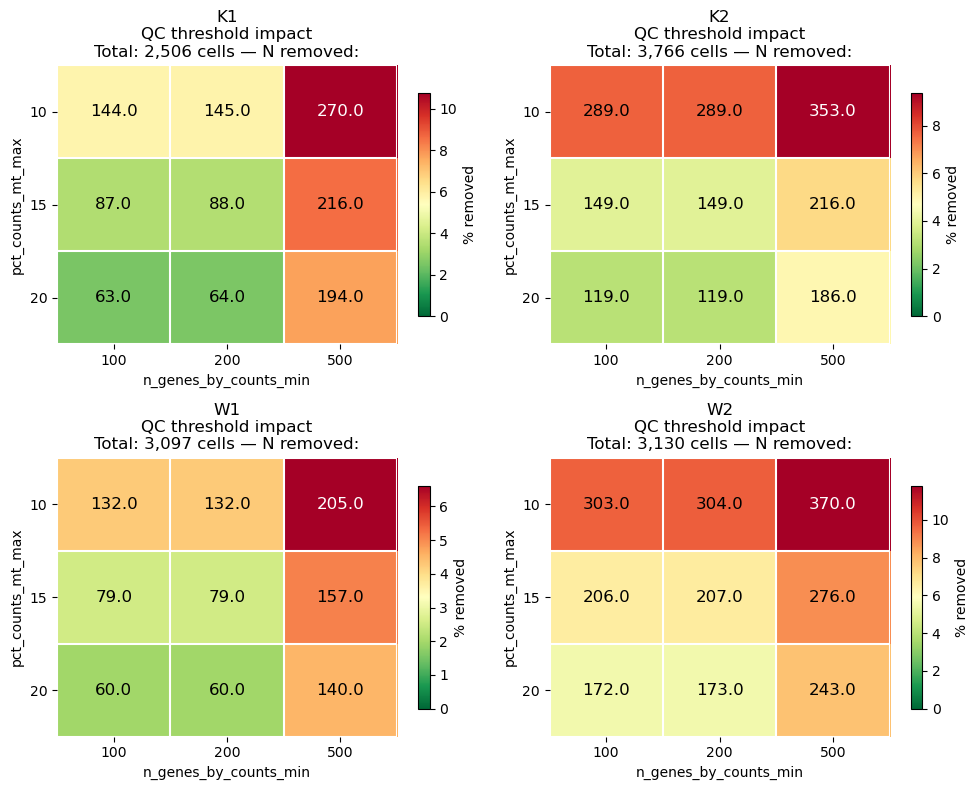

In [16]:
# Evaluate filtering thresholds: test multiple combinations to find optimal cutoffs
summary_dfs = {}
for sample, adata in adatas_dic["scroublet"].items():
    # For each sample, evaluate QC thresholds with different min/max values
    # This returns a dataframe showing cell counts for each combination
    summary_dfs[sample] = EvaluateQcThresholds(
        adata,
        # Test combinations: gene count minimum (100, 200, 500) and MT% maximum (10, 15, 20)
        # These thresholds are reasonable starting points for most tissues
        {
            "n_genes_by_counts": {
                "min": [100, 200, 500]  # Minimum genes to keep
                # 100: very lenient (keep most cells, including low-quality)
                # 200: moderate (our chosen threshold)
                # 500: strict (high quality but lose more cells)
            },
            "pct_counts_mt": {
                "max": [10, 15, 20]  # Maximum MT% to keep
                # 10: strict (only pristine cells)
                # 15: moderate (our chosen threshold, standard for most tissues)
                # 20: lenient (allows some stressed cells)
            }
        },
        method="absolute",  # Method: absolute thresholds (not relative/quantile-based)
    )

# Visualize threshold evaluation results as a grid
# Each cell shows remaining cell count for that threshold pair
# Helps identify the "sweet spot" where cell retention is high (~75-90%)
# but quality metrics improve
_ = PlotQcThresholdsGrid(
    summary_dfs,
    x="n_genes_by_counts_min",
    y="pct_counts_mt_max",
    ncols=2,  # 2 columns: K samples | W samples
)

## APPLY CHOSEN FILTERS

Apply optimized parameters to remove low-quality cells and create the final QC-filtered dataset.

### Decision: gene_min = 200 | MT%_max = 15

**Rationale:**

| **Parameter** | **Threshold** | **Why** |
|:---|:---|:---|
| **Gene count** | ≥200 | Standard for mammalian tissue; filters empty droplets & severe degradation |
| **MT%** | ≤15% | Literature standard; removes stressed/apoptotic cells without over-filtering |

**Expected outcome:**
- ✓ ~85–90% cell retention
- ✓ Singlet-only, high-quality dataset
- ✓ Ready for downstream analysis (normalization, HVG, clustering, etc.)

**Output characteristics:**
- All cells: ≥200 genes
- All cells: ≤15% mitochondrial reads
- Sample metadata preserved
- All cells pass doublet and ambient RNA filters

In [ ]:
# Define filtering cutoffs - chosen based on threshold evaluation grid above
cutoffs = {
    "n_genes_by_counts": {"min": 200},  # Keep cells with ≥200 detected genes
    # Removes: empty droplets (<100 genes), low-quality/degraded cells
    "pct_counts_mt":     {"max": 15},   # Keep cells with ≤15% mitochondrial counts
    # Removes: stressed cells, apoptotic cells, or cells with poor recovery
}

# Filter cells for each sample based on chosen thresholds
# This creates a new dataset with only high-quality cells
adatas_dic["filtered"] = {
    sample: FilterQcCells(adata, cutoffs)
    for sample, adata in adatas_dic["scroublet"].items()
}

# Display filtered datasets with cell count changes shown in output
# Look at output to verify that:
#   - Cell counts decreased as expected
#   - Reduction is reasonable (typically 10-30% removal)
#   - All samples retained sufficient cells for downstream analysis
adatas_dic["filtered"]

2506 → 2418 células  (88 removidas)
3766 → 3617 células  (149 removidas)
3097 → 3018 células  (79 removidas)
3130 → 2923 células  (207 removidas)


{'K1': AnnData object with n_obs × n_vars = 2418 × 23180
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet'
     var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
     uns: 'qc_params', 'scrublet'
     layers: 'counts', 'soupX_counts',
 'K2': AnnData object with n_obs × n_vars = 3617 × 25103
     obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_co

## VALIDATE QC IMPROVEMENTS

Verify that filtering achieved its intended goal: quality improvement without excessive data loss.

### Expected Observations ✓

After filtering, you should see:

- ✓ **Lower MT% distribution** — High-MT cells removed  
- ✓ **Same or higher median gene count** — Low-count outliers removed  
- ✓ **Tighter distributions** — More concentrated, less spread  
- ✓ **Fewer extreme outliers** — "Cleaner" data visually  
- ✓ **Clear quality improvement** — Before vs. after plots show benefit  

### Red Flags ❌

If you observe these, reconsider your thresholds:

| **Red Flag** | **Interpretation** |
|:---|:---|
| **>50% cell loss** | Thresholds too strict — may over-filter |
| **No quality improvement** | Thresholds too lenient — not filtering enough |
| **Large sample variation** | Samples have different quality — consider per-sample params |
| **Unexpected distribution shifts** | Check for data anomalies or verify input quality |

### Validation Outputs

- ✓ Violin plots (before/after)
- ✓ Boxplots (gene count distribution)
- ✓ Summary table (cell counts per sample)

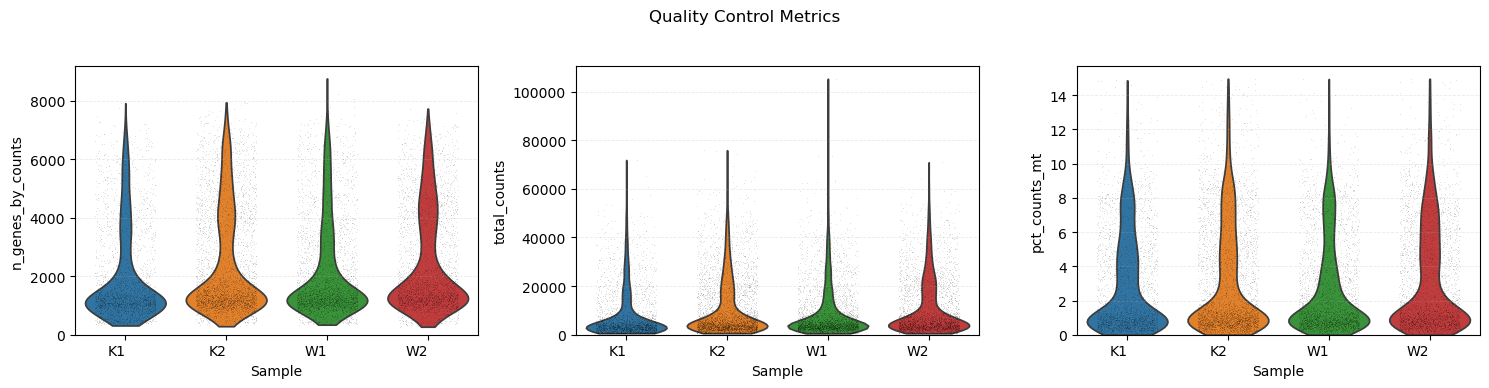

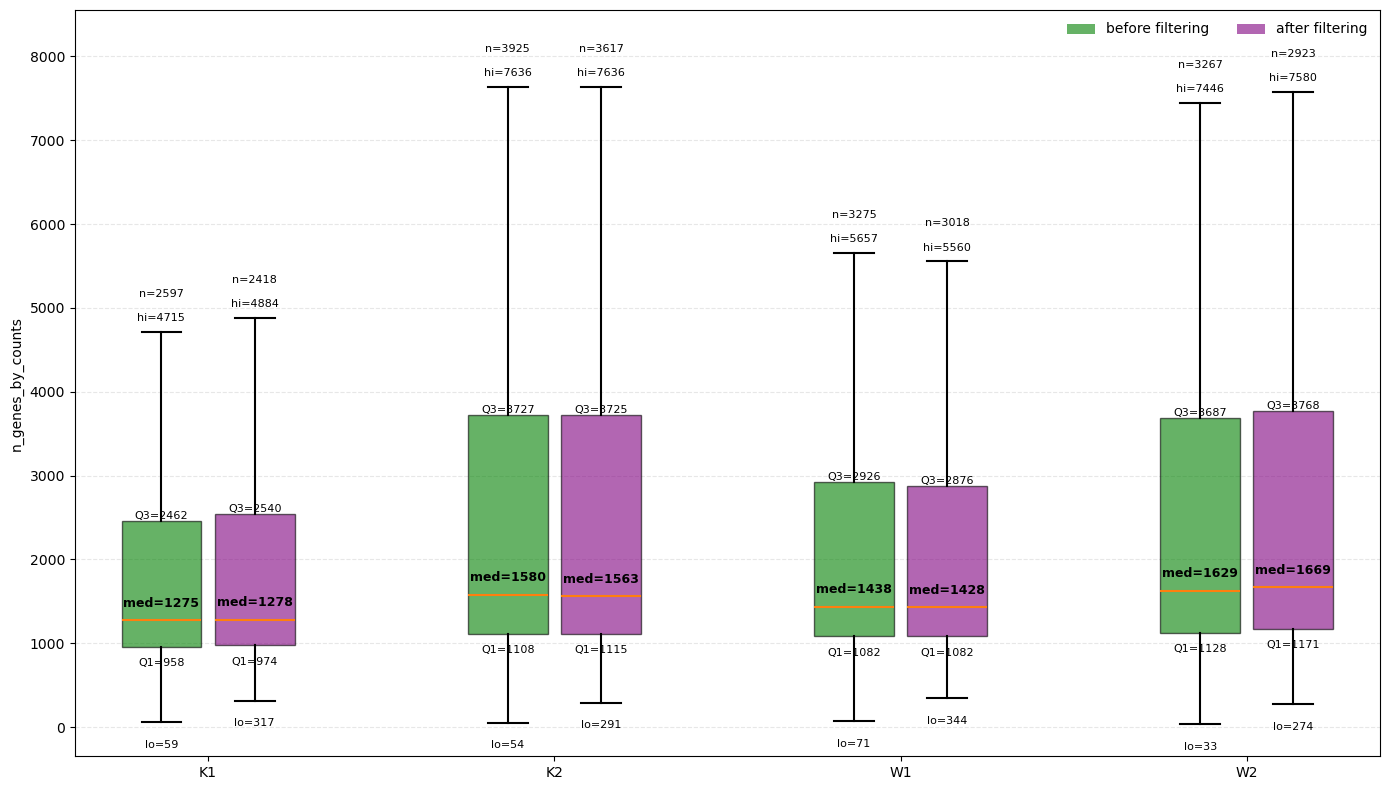

,K1,K2,W1,W2
Initial Cell Counts,2597.00,3925.00,3275.00,3267.00
Final Cell Counts,2418.00,3617.00,3018.00,2923.00
Initial Gene Counts,23180.00,25103.00,24128.00,24510.00
Final Gene Counts,23180.00,25103.00,24128.00,24510.00
Initial N Cell by Genes (Median),30.00,37.00,34.00,33.00
Final N Cell by Genes (Median),28.00,35.00,32.00,31.00
Initial N Genes by Cells (Median),1275.00,1580.00,1438.00,1629.00
Final N Genes by Cells (Median),1278.50,1563.00,1428.00,1669.00
Initial Pct counts in top 20 genes (Median),32.29,33.35,34.23,34.28
Final Pct counts in top 20 genes (Median),32.13,33.25,34.05,33.84


In [18]:
# ==============================================================================
# STEP 7: VISUALIZE QC IMPROVEMENTS
# ==============================================================================
# Compare QC metrics before and after filtering to verify quality improvement.
# Good signs:
#   - Median gene count unchanged or higher (filtering removed low-count cells)
#   - MT% distribution shifted lower (removed high-MT cells)
#   - Overall distribution becomes more concentrated (outliers removed)

# Visualize QC metrics of filtered dataset (full range)
_,_ = PlotQCViolinsGrid(sc.concat(list(adatas_dic["filtered"].values())))

# Boxplot comparison: gene count distribution before (raw) and after filtering
# Shows median, quartiles, and outliers
# Expect: similar or slightly higher median, tighter distribution after filtering
PlotQcBoxplots(
    adatas_before=adatas_dic["sevenbridges"],  # Raw data (all cells)
    adatas_after=adatas_dic["filtered"],       # Filtered data (singlets + QC)
    metric="n_genes_by_counts",
)

# Generate summary table showing filtering statistics for each sample
# Columns: original count, removed count, remaining count, % retained
# Helps assess filtering stringency and data loss
summary_table = QcSummaryTable(
    adatas_before=adatas_dic["sevenbridges"],  # Starting dataset (all cells from SevenBridges)
    adatas_after=adatas_dic["filtered"],       # Final filtered dataset
    cutoffs=cutoffs,  # The thresholds applied
)
display(summary_table)

# **STEP 8:** CONCATENATE & SAVE FINAL DATASET


Merge all QC-filtered samples into a single AnnData object for downstream analysis.

### What We Preserve

✓ **Sample metadata** — K1, K2, W1, W2 identifiers  
✓ **Biological condition** — KO vs WT labels  
✓ **Cell annotations** — All .obs metadata  
✓ **Count layers** — SoupX-corrected counts preserved  
✓ **Gene annotations** — All .var metadata  

### Output File

**Location:** `03sx.NeuFfar2_QC_filtered.h5ad`

**Content:**
- ~11,000 high-quality cells (singlets, gene_min=200, MT%_max=15)
- 23,000–25,000 genes per sample
- Metadata: sample, condition, QC metrics
- Layers: original counts, SoupX-corrected counts

### Next Steps (Downstream)

This dataset is ready for:

1. **Normalization** — Log-transformation, library size scaling
2. **HVG selection** — Identify highly variable genes
3. **Dimensionality reduction** — PCA, UMAP
4. **Clustering** — Identify cell types
5. **Cell annotation** — Assign biological identities
6. **Differential expression** — Compare KO vs WT

---

**✓ QC pipeline complete!** Your data is now clean and ready for analysis.

In [ ]:
# ==============================================================================
# STEP 8: CONCATENATE SAMPLES AND SAVE
# ==============================================================================
# Merge all QC-filtered samples into a single AnnData object for downstream analysis.
# Preserves sample information in .obs metadata for:
#   - Batch correction (if needed)
#   - Per-sample QC assessment
#   - Differential expression (when comparing K vs W)

# Concatenate all filtered samples into a single AnnData object
# Preserves sample and condition metadata from .obs (all annotations are kept)
adata_cat = CatAdata([adatas_dic['filtered'][sample] for sample in SAMPLES], SAMPLES)

# Store the QC-filtered counts as a layer for reference
# This preserves the raw (or SoupX-corrected) counts before normalization
# Useful for: re-normalizing with different methods, batch correction validation
adata_cat.layers['QC_filtered'] = adata_cat.X

# Save concatenated, QC-filtered dataset to disk
# This is the starting point for downstream analysis:
#   - Normalization
#   - HVG selection
#   - Dimensionality reduction (PCA, UMAP)
#   - Clustering and cell type annotation

adata_cat.write("/media/tahila/DADOS/HD/2605_scNeu/scNeuFfar2/03sx.NeuFfar2_QC_filtered.h5ad")
print("✓ QC-filtered dataset saved successfully")

INFO:sctools.io:CatAdata: 4 samples -> 11976 cells x 27992 genes.


✓ QC-filtered dataset saved successfully


In [20]:
adata_cat

AnnData object with n_obs × n_vars = 11976 × 27992
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet'
    uns: 'qc_params', 'scrublet'
    layers: 'counts', 'soupX_counts', 'QC_filtered'

---

## Acknowledgments: AI-Assisted Development & Scientific Foundations

**Use of Claude Code (Claude AI, Anthropic)**

This tutorial notebook was developed with assistance from Claude Code to optimize code structure, enhance documentation, and create comprehensive explanatory content.

**Specific contributions of AI assistance:**
- Refactoring and streamlining of analysis pipelines to improve clarity and reproducibility
- Development of comprehensive inline code comments explaining biological and technical concepts
- Creation of step-by-step tutorial structure with scientific rationale for each analysis stage
- Generation of interpretation guidelines for QC metrics, visualization outputs, and threshold selection strategies

**Important transparency statement:**

- All code modifications, parameter choices, and analytical decisions were implemented within the author's established sctools framework and validated methodologies
- All written content, code comments, and explanatory material was thoroughly reviewed and verified by the author against current scRNA-seq best practices and literature standards  
- The biological accuracy, scientific validity, and reproducibility of the analysis were manually confirmed through inspection of outputs and cross-validation with established protocols

**Conclusion:**

This notebook exemplifies responsible integration of AI-assisted tools in computational biology: automation of documentation and code clarity acceleration, combined with rigorous human expertise, peer-reviewed literature foundations, and scientific validation ensuring correctness and reproducibility.